## Cell 1 — Setup: Reproducibility, GPU Check, Dataset Discovery

Fixes all random seeds for reproducibility, verifies GPU availability, and performs a
full recursive scan of `/kaggle/input` to confirm the exact folder structure of both
attached datasets (RVF10K and the StyleGAN3 Real/Fake Faces set) before any path-dependent
code is written.

In [1]:
# === NOTEBOOK 01 — CELL 1: Setup — reproducibility, GPU check, dataset discovery ===

import os, random, warnings
import numpy as np
import tensorflow as tf

warnings.filterwarnings("ignore")

# --- Reproducibility ---
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# --- Working dirs ---
WORKING_DIR = "/kaggle/working"
for sub in ["results", "gradcam", "checkpoints", "logs"]:
    os.makedirs(f"{WORKING_DIR}/{sub}", exist_ok=True)

# --- GPU check ---
gpus = tf.config.list_physical_devices('GPU')
print(f"GPUs detected: {len(gpus)}")
for g in gpus:
    print(f"  -> {g}")
print(f"\nTensorFlow version: {tf.__version__}")

# --- Full recursive discovery of /kaggle/input (no depth cap this time — ---
# --- we need to see all the way down to the image files/subfolders)     ---
print("\nFull contents of /kaggle/input:\n")
for dirname, subdirs, filenames in os.walk("/kaggle/input"):
    depth = dirname.replace("/kaggle/input", "").count(os.sep)
    indent = "  " * depth
    if filenames:
        # Show folder + a sample of file names/extensions so we can identify image dirs
        exts = sorted(set(os.path.splitext(f)[1].lower() for f in filenames))
        print(f"{indent}{dirname}  ({len(filenames)} files, ext={exts})")
    else:
        print(f"{indent}{dirname}")

GPUs detected: 2
  -> PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  -> PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')

TensorFlow version: 2.20.0

Full contents of /kaggle/input:

/kaggle/input
  /kaggle/input/datasets
    /kaggle/input/datasets/troykueh
      /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3  (1 files, ext=['.csv'])
        /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3/Real faces  (10000 files, ext=['.png'])
        /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3/Fake faces  (10000 files, ext=['.png'])
    /kaggle/input/datasets/sachchitkunichetty
      /kaggle/input/datasets/sachchitkunichetty/rvf10k  (2 files, ext=['.csv'])
        /kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k
          /kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k/valid
            /kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k/valid/fake  (1500 files, ext=['.jpg'])
            /kaggle/input/d

## Cell 2 — Build Combined Manifest (RVF10K + StyleGAN3 Real/Fake Faces)

In [2]:
# === NOTEBOOK 01 — CELL 2: Build combined manifest from RVF10K + StyleGAN3 Real/Fake Faces ===

import os
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

LABEL_MAP = {"fake": 0, "real": 1}

# --- Dataset roots ---
RVF10K_ROOT     = "/kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k"
STYLEGAN3_ROOT  = "/kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3"

def list_images(folder, exts=(".jpg", ".jpeg", ".png")):
    """Case-insensitive file listing — avoids missing files on case-sensitive Linux glob."""
    folder = Path(folder)
    return [str(folder / f) for f in os.listdir(folder) if f.lower().endswith(exts)]

records = []

# --- 1) RVF10K: has its own train/valid split — we IGNORE it and pool all 10,000 images, ---
# --- then build our own stratified split so RVF10K and StyleGAN3 share one consistent scheme ---
for split_folder in ["train", "valid"]:
    for label_name, label_val in LABEL_MAP.items():
        folder = Path(RVF10K_ROOT) / split_folder / label_name
        for p in list_images(folder):
            records.append({"path": p, "label": label_val, "label_name": label_name,
                             "source_dataset": "rvf10k"})

# --- 2) StyleGAN3 Real/Fake Faces: flat folders, no pre-existing split ---
stylegan3_dirs = {"real": "Real faces", "fake": "Fake faces"}
for label_name, folder_name in stylegan3_dirs.items():
    folder = Path(STYLEGAN3_ROOT) / folder_name
    for p in list_images(folder):
        records.append({"path": p, "label": LABEL_MAP[label_name], "label_name": label_name,
                         "source_dataset": "stylegan3"})

manifest_df = pd.DataFrame(records)

print("Combined dataset — before split:")
print(f"Total images: {len(manifest_df)}  (expected 30,000 -> 10,000 RVF10K + 20,000 StyleGAN3)")
print(manifest_df.groupby(["source_dataset", "label_name"]).size())

# --- Sanity check: confirm a random sample of paths actually resolve on disk ---
print("\nRandom path sanity check:")
for _, row in manifest_df.sample(5, random_state=SEED).iterrows():
    print(f"  [{row['source_dataset']}/{row['label_name']}] {row['path']}  exists={os.path.exists(row['path'])}")

# --- Stratify jointly on source_dataset + label so train/val/test each keep a ---
# --- proportional mix of both datasets and both classes (70/20/10 split) ---
manifest_df["strata"] = manifest_df["source_dataset"] + "_" + manifest_df["label_name"]

train_df, temp_df = train_test_split(
    manifest_df, test_size=0.30, stratify=manifest_df["strata"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=1/3, stratify=temp_df["strata"], random_state=SEED
)  # 0.30 * (1/3) = 0.10 of the full set -> overall 70/20/10

train_df = train_df.copy(); train_df["split"] = "train"
val_df   = val_df.copy();   val_df["split"]   = "val"
test_df  = test_df.copy();  test_df["split"]  = "test"

manifest_df = pd.concat([train_df, val_df, test_df], ignore_index=True).drop(columns=["strata"])

print("\nFinal split sizes:")
print(manifest_df["split"].value_counts())
print("\nSplit x source_dataset x label breakdown:")
print(manifest_df.groupby(["split", "source_dataset", "label_name"]).size())

# --- Save manifest — single source of truth for every downstream notebook ---
manifest_path = f"{WORKING_DIR}/results/manifest.csv"
manifest_df.to_csv(manifest_path, index=False)
print(f"\nSaved combined manifest: {manifest_path}")

Combined dataset — before split:
Total images: 30000  (expected 30,000 -> 10,000 RVF10K + 20,000 StyleGAN3)
source_dataset  label_name
rvf10k          fake           5000
                real           5000
stylegan3       fake          10000
                real          10000
dtype: int64

Random path sanity check:
  [rvf10k/fake] /kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k/train/fake/J1CVDK274Q.jpg  exists=True
  [stylegan3/fake] /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3/Fake faces/fake_5949.png  exists=True
  [stylegan3/fake] /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3/Fake faces/fake_1628.png  exists=True
  [stylegan3/fake] /kaggle/input/datasets/troykueh/real-vs-fake-faces-stylegan3/Fake faces/fake_2058.png  exists=True
  [rvf10k/fake] /kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k/train/fake/B18JNOJ3K3.jpg  exists=True

Final split sizes:
split
train    21000
val       6000
test      3000
Name: count, dtype: int64

Split x

## Cell 3 — Build tf.data Pipelines (Mixed .jpg/.png, Split-Aware, Leakage-Checked)

I0000 00:00:1784381334.910979      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784381334.913935      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


train_ds: 21000 images, 657 batches
val_ds:   6000 images, 188 batches
test_ds:  3000 images, 94 batches

Leakage check passed: train/val/test are fully disjoint (0 overlapping paths).


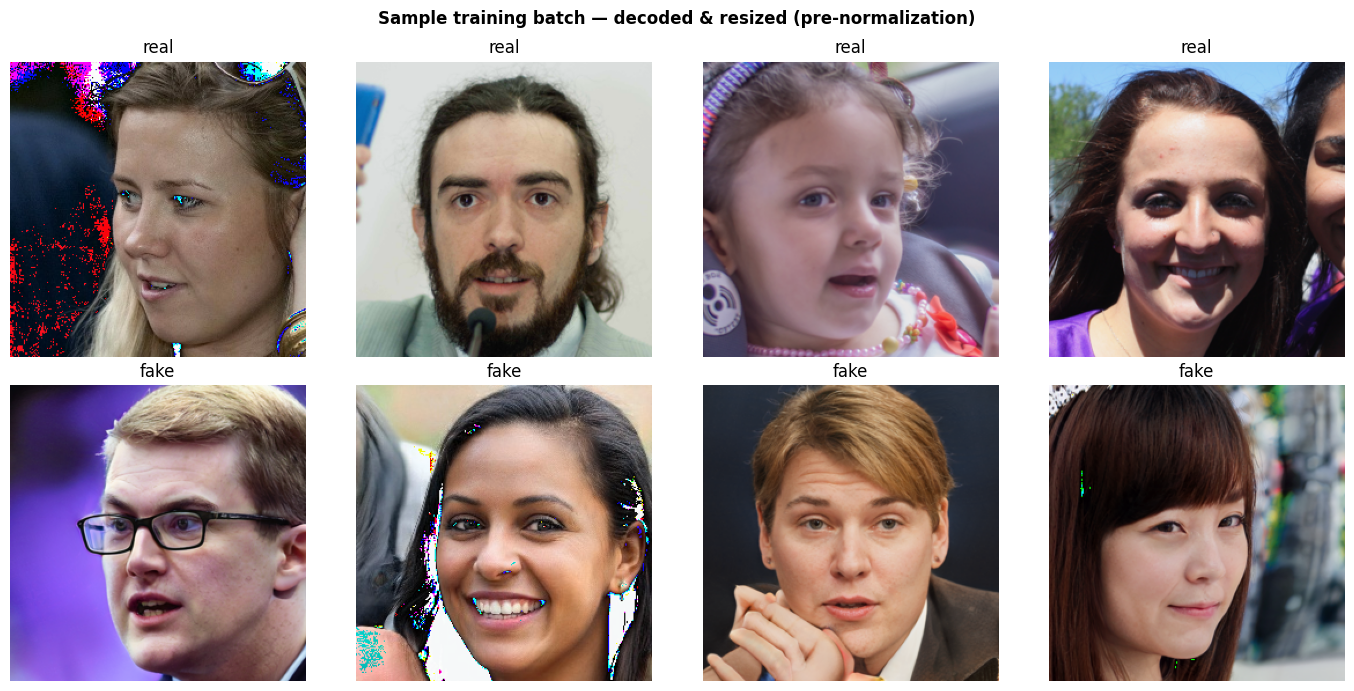

In [3]:
# === NOTEBOOK 01 — CELL 3: Build tf.data pipelines (mixed .jpg/.png, split-aware) ===

import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = (256, 256)
BATCH_SIZE = 32

# --- Safety net: reload manifest from disk if this cell is ever run after a kernel restart ---
if "manifest_df" not in globals():
    manifest_df = pd.read_csv(f"{WORKING_DIR}/results/manifest.csv")
    print(f"Reloaded manifest from disk: {len(manifest_df)} rows")

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    # decode_image (not decode_jpeg) — RVF10K is .jpg, StyleGAN3 is .png.
    # expand_animations=False forces a static shape so .resize()/.batch() work in graph mode.
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)
    # NOTE: pixel-range normalization (e.g. VGG/ResNet preprocess_input, or /255.) is NOT
    # applied here on purpose — it's backbone-specific and gets added in Cell 4 as one more
    # .map() step, so this pipeline doesn't need to be rebuilt if the architecture changes.
    return img, label

def augment_image(img, label):
    # Light, label-preserving augmentation only — aggressive geometric/color distortion
    # can wash out the compression/GAN artifacts the model is actually trying to learn
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta=0.08)
    img = tf.image.random_contrast(img, lower=0.92, upper=1.08)
    return img, label

def build_dataset(manifest_df, split, shuffle=False, augment=False):
    df = manifest_df[manifest_df["split"] == split]
    paths = df["path"].tolist()
    labels = df["label"].tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(augment_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds, len(paths)

# --- Build all three splits — train gets augmentation + shuffle, val/test get neither ---
train_ds, n_train = build_dataset(manifest_df, split="train", shuffle=True,  augment=True)
val_ds,   n_val   = build_dataset(manifest_df, split="val",   shuffle=False, augment=False)
test_ds,  n_test  = build_dataset(manifest_df, split="test",  shuffle=False, augment=False)

print(f"train_ds: {n_train} images, {len(train_ds)} batches")
print(f"val_ds:   {n_val} images, {len(val_ds)} batches")
print(f"test_ds:  {n_test} images, {len(test_ds)} batches")

# --- Leakage check: explicit, printed proof that no path appears in more than one split ---
train_paths = set(manifest_df[manifest_df["split"] == "train"]["path"])
val_paths   = set(manifest_df[manifest_df["split"] == "val"]["path"])
test_paths  = set(manifest_df[manifest_df["split"] == "test"]["path"])

assert train_paths.isdisjoint(val_paths),  "Leakage detected: train/val overlap!"
assert train_paths.isdisjoint(test_paths), "Leakage detected: train/test overlap!"
assert val_paths.isdisjoint(test_paths),   "Leakage detected: val/test overlap!"
print("\nLeakage check passed: train/val/test are fully disjoint (0 overlapping paths).")

# --- Visual sanity check: confirm decode/resize worked on both file formats ---
class_names_rev = {0: "fake", 1: "real"}
sample_imgs, sample_labels = next(iter(train_ds.take(1)))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_imgs[i].numpy().astype("uint8"))
    ax.set_title(class_names_rev[int(sample_labels[i])])
    ax.axis("off")
plt.suptitle("Sample training batch — decoded & resized (pre-normalization)", fontweight="bold")
plt.tight_layout()
plt.show()

## Cell 4 — Load Trained Model + Notebook 01's Own Manifest (Correct Test Set)

In [4]:
# === CELL 4: Load best_model.keras + Notebook 01's own manifest (authoritative test split) ===

import pandas as pd
from pathlib import Path
from tensorflow.keras.applications.vgg19 import preprocess_input

# --- Auto-discover NB01's root: search for the folder containing checkpoints/best_model.keras ---
# (robust to exact username/slug — avoids hardcoding a path we haven't confirmed)
nb01_root = None
for dirname, subdirs, filenames in os.walk("/kaggle/input/notebooks"):
    if "best_model.keras" in filenames and Path(dirname).name == "checkpoints":
        nb01_root = str(Path(dirname).parent)
        break

assert nb01_root is not None, "Could not find best_model.keras under /kaggle/input/notebooks — is the training notebook attached as an Input?"
print(f"Found NB01 root: {nb01_root}")

# --- Load the trained model (best-epoch weights, from ModelCheckpoint) ---
model_path = f"{nb01_root}/checkpoints/best_model.keras"
model = tf.keras.models.load_model(model_path)
print(f"\nLoaded model from: {model_path}")
print(f"Total params: {model.count_params():,}")

# --- Load NB01's OWN manifest — this is the exact split the model trained on. ---
# --- Do NOT reuse the local manifest_df from Cells 1-3 (different split method = leakage risk). ---
nb01_manifest_path = f"{nb01_root}/results/manifest.csv"
nb01_manifest_df = pd.read_csv(nb01_manifest_path)
print(f"\nLoaded NB01 manifest from: {nb01_manifest_path}")
print(nb01_manifest_df.groupby(["dataset", "split"]).size().unstack(fill_value=0))

# --- Same constants/preprocessing as training (VGG19 preprocess_input, 256x256) ---
IMG_SIZE = (256, 256)
BATCH_SIZE = 64

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = preprocess_input(img)
    return img, label

def build_test_dataset(df):
    paths = df["path"].tolist()
    labels = df["label"].tolist()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds, len(paths)

# --- Pooled test set (both datasets combined) ---
test_df = nb01_manifest_df[nb01_manifest_df["split"] == "test"]
test_ds, n_test = build_test_dataset(test_df)

# --- Per-dataset test sets (for cross-dataset generalization breakdown) ---
rvf10k_test_df = test_df[test_df["dataset"] == "rvf10k"]
sgan3_test_df  = test_df[test_df["dataset"] == "sgan3"]
rvf10k_test_ds, n_rvf10k_test = build_test_dataset(rvf10k_test_df)
sgan3_test_ds,  n_sgan3_test  = build_test_dataset(sgan3_test_df)

print(f"\nPooled test set:   {n_test} images")
print(f"  RVF10K test:     {n_rvf10k_test} images")
print(f"  StyleGAN3 test:  {n_sgan3_test} images")

# --- Sanity check ---
sample_path = test_df["path"].iloc[0]
print(f"\nSample test image path: {sample_path}")
print(f"File exists: {os.path.exists(sample_path)}")

Found NB01 root: /kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd

Loaded model from: /kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/checkpoints/best_model.keras
Total params: 22,651,457

Loaded NB01 manifest from: /kaggle/input/notebooks/nasrullahbaber/improved-hybrid-deepfake-detector-dfd/results/manifest.csv
split    test  train   val
dataset                   
rvf10k   1000   7000  2000
sgan3    2000  14000  4000

Pooled test set:   3000 images
  RVF10K test:     1000 images
  StyleGAN3 test:  2000 images

Sample test image path: /kaggle/input/datasets/sachchitkunichetty/rvf10k/rvf10k/train/fake/V0LHC11OV8.jpg
File exists: True


## Cell 5 — Predictions + Full Evaluation Metrics (Pooled, RVF10K-only, StyleGAN3-only)

In [5]:
# === CELL 5: Predictions + full evaluation metrics — pooled + per-dataset breakdown ===

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
import json

def evaluate_on(ds, df, label):
    """Run predictions + compute the full metric set for one test subset."""
    y_true = df["label"].to_numpy()
    y_pred_proba = model.predict(ds, verbose=0).flatten()
    y_pred = (y_pred_proba >= 0.5).astype(int)

    assert len(y_true) == len(y_pred), f"[{label}] Mismatch between labels and predictions."

    metrics = {
        "n": int(len(y_true)),
        "accuracy":  float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred)),
        "recall":    float(recall_score(y_true, y_pred)),
        "f1_score":  float(f1_score(y_true, y_pred)),
        "auc_roc":   float(roc_auc_score(y_true, y_pred_proba)),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
    }

    print("=" * 55)
    print(f"{label}  (n={metrics['n']})")
    print("=" * 55)
    print(f"Accuracy:  {metrics['accuracy']:.4f}")
    print(f"Precision: {metrics['precision']:.4f}")
    print(f"Recall:    {metrics['recall']:.4f}")
    print(f"F1 Score:  {metrics['f1_score']:.4f}")
    print(f"AUC-ROC:   {metrics['auc_roc']:.4f}")
    print(f"\nConfusion Matrix (rows=true, cols=predicted, 0=fake, 1=real):")
    print(np.array(metrics["confusion_matrix"]))
    print(f"\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=["fake", "real"], digits=4))
    print()

    return metrics, y_true, y_pred_proba

# --- Evaluate all three ---
pooled_metrics,  y_true_pooled,  y_proba_pooled  = evaluate_on(test_ds,         test_df,         "POOLED TEST SET (RVF-10K + StyleGAN3)")
rvf10k_metrics,  y_true_rvf10k,  y_proba_rvf10k  = evaluate_on(rvf10k_test_ds,  rvf10k_test_df,  "RVF-10K TEST SET ONLY")
sgan3_metrics,   y_true_sgan3,   y_proba_sgan3   = evaluate_on(sgan3_test_ds,   sgan3_test_df,   "STYLEGAN3 TEST SET ONLY")

# --- Save everything for the paper ---
results_dict = {
    "pooled": pooled_metrics,
    "rvf10k_only": rvf10k_metrics,
    "stylegan3_only": sgan3_metrics,
}
results_path = f"{WORKING_DIR}/results/test_set_metrics.json"
with open(results_path, "w") as f:
    json.dump(results_dict, f, indent=2)
print(f"Saved: {results_path}")

POOLED TEST SET (RVF-10K + StyleGAN3)  (n=3000)
Accuracy:  0.9517
Precision: 0.9520
Recall:    0.9513
F1 Score:  0.9517
AUC-ROC:   0.9894

Confusion Matrix (rows=true, cols=predicted, 0=fake, 1=real):
[[1428   72]
 [  73 1427]]

Classification report:
              precision    recall  f1-score   support

        fake     0.9514    0.9520    0.9517      1500
        real     0.9520    0.9513    0.9517      1500

    accuracy                         0.9517      3000
   macro avg     0.9517    0.9517    0.9517      3000
weighted avg     0.9517    0.9517    0.9517      3000


RVF-10K TEST SET ONLY  (n=1000)
Accuracy:  0.9680
Precision: 0.9718
Recall:    0.9640
F1 Score:  0.9679
AUC-ROC:   0.9943

Confusion Matrix (rows=true, cols=predicted, 0=fake, 1=real):
[[486  14]
 [ 18 482]]

Classification report:
              precision    recall  f1-score   support

        fake     0.9643    0.9720    0.9681       500
        real     0.9718    0.9640    0.9679       500

    accuracy            

## Cell 6 — Confusion Matrix + Three-Way ROC Curve (Pooled vs. Per-Dataset)

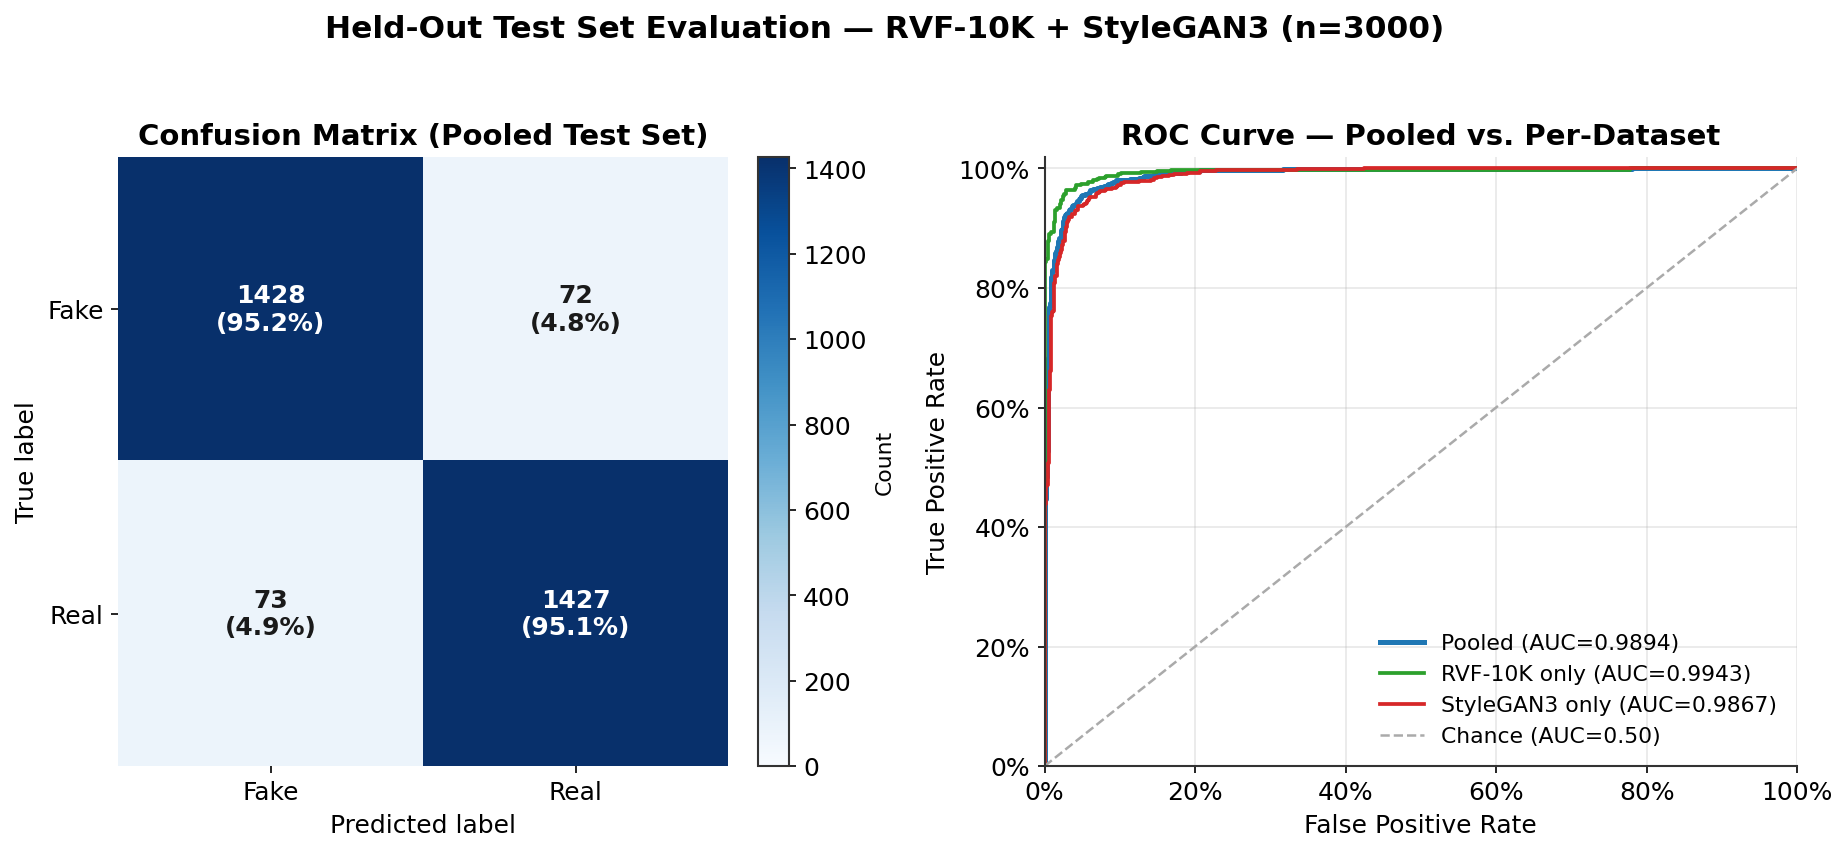

Saved: /kaggle/working/results/confusion_matrix_roc.png
Saved: /kaggle/working/results/confusion_matrix_roc.pdf  (vector format — use this one in the paper)


In [6]:
# === CELL 6: Confusion Matrix + three-way ROC curve overlay (publication-quality) ===

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import roc_curve

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.edgecolor": "#333333",
    "axes.linewidth": 1.0,
    "legend.fontsize": 10.5,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)

# --- Confusion Matrix (pooled) ---
ax = axes[0]
cm_pooled = np.array(pooled_metrics["confusion_matrix"])
class_names = ["Fake", "Real"]
im = ax.imshow(cm_pooled, cmap="Blues", vmin=0)

row_sums = cm_pooled.sum(axis=1, keepdims=True)
for i in range(cm_pooled.shape[0]):
    for j in range(cm_pooled.shape[1]):
        count = cm_pooled[i, j]
        pct = 100 * count / row_sums[i, 0]
        text_color = "white" if count > cm_pooled.max() / 2 else "#1a1a1a"
        ax.text(j, i, f"{count}\n({pct:.1f}%)", ha="center", va="center",
                 color=text_color, fontsize=12, fontweight="bold")

ax.set_xticks([0, 1]); ax.set_xticklabels(class_names)
ax.set_yticks([0, 1]); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix (Pooled Test Set)")
for spine in ax.spines.values():
    spine.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Count", fontsize=10.5)

# --- Three-way ROC overlay ---
ax = axes[1]
roc_configs = [
    (y_true_pooled, y_proba_pooled, f"Pooled (AUC={pooled_metrics['auc_roc']:.4f})", "#1f77b4", 2.4),
    (y_true_rvf10k, y_proba_rvf10k, f"RVF-10K only (AUC={rvf10k_metrics['auc_roc']:.4f})", "#2ca02c", 1.8),
    (y_true_sgan3,  y_proba_sgan3,  f"StyleGAN3 only (AUC={sgan3_metrics['auc_roc']:.4f})", "#d62728", 1.8),
]
for y_t, y_p, label, color, lw in roc_configs:
    fpr, tpr, _ = roc_curve(y_t, y_p)
    ax.plot(fpr, tpr, color=color, linewidth=lw, label=label)

ax.plot([0, 1], [0, 1], color="#aaaaaa", linewidth=1.2, linestyle="--", label="Chance (AUC=0.50)")
ax.set_xlim([0.0, 1.0]); ax.set_ylim([0.0, 1.02])
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve — Pooled vs. Per-Dataset")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

fig.suptitle("Held-Out Test Set Evaluation — RVF-10K + StyleGAN3 (n=3000)",
             fontsize=15, fontweight='bold', y=1.03)
fig.tight_layout()

png_path = f"{WORKING_DIR}/results/confusion_matrix_roc.png"
pdf_path = f"{WORKING_DIR}/results/confusion_matrix_roc.pdf"
fig.savefig(png_path, dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(pdf_path, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Saved: {png_path}")
print(f"Saved: {pdf_path}  (vector format — use this one in the paper)")

## Cell 7 — Save Paper-Ready Results Table + Full Per-Image Predictions

In [7]:
# === CELL 7: Save paper-ready results table + full per-image predictions ===

# --- 1) Flat results table for the paper ---
table_rows = []
for subset_name, metrics in [("Pooled", pooled_metrics), ("RVF-10K only", rvf10k_metrics), ("StyleGAN3 only", sgan3_metrics)]:
    table_rows.append({
        "Test Subset": subset_name,
        "n": metrics["n"],
        "Accuracy": round(metrics["accuracy"], 4),
        "Precision": round(metrics["precision"], 4),
        "Recall": round(metrics["recall"], 4),
        "F1 Score": round(metrics["f1_score"], 4),
        "AUC-ROC": round(metrics["auc_roc"], 4),
    })
results_table = pd.DataFrame(table_rows)
table_path = f"{WORKING_DIR}/results/results_table.csv"
results_table.to_csv(table_path, index=False)
print("Results table:")
print(results_table.to_string(index=False))
print(f"\nSaved: {table_path}")

# --- 2) Full per-image predictions — path, dataset, true/pred label, probability, correctness ---
def build_predictions_df(df, y_true, y_proba):
    out = df[["path", "dataset", "label"]].copy().reset_index(drop=True)
    out["true_label"] = out.pop("label")
    out["pred_proba"] = y_proba
    out["pred_label"] = (y_proba >= 0.5).astype(int)
    out["correct"] = (out["true_label"] == out["pred_label"])
    return out

predictions_df = build_predictions_df(test_df, y_true_pooled, y_proba_pooled)
predictions_path = f"{WORKING_DIR}/results/test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

print(f"\nSaved per-image predictions: {predictions_path}  ({len(predictions_df)} rows)")
print(f"Misclassified: {(~predictions_df['correct']).sum()}  |  Correct: {predictions_df['correct'].sum()}")
print("\nBreakdown of misclassifications by dataset:")
print(predictions_df[~predictions_df["correct"]].groupby("dataset").size())

Results table:
   Test Subset    n  Accuracy  Precision  Recall  F1 Score  AUC-ROC
        Pooled 3000    0.9517     0.9520  0.9513    0.9517   0.9894
  RVF-10K only 1000    0.9680     0.9718  0.9640    0.9679   0.9943
StyleGAN3 only 2000    0.9435     0.9422  0.9450    0.9436   0.9867

Saved: /kaggle/working/results/results_table.csv

Saved per-image predictions: /kaggle/working/results/test_predictions.csv  (3000 rows)
Misclassified: 145  |  Correct: 2855

Breakdown of misclassifications by dataset:
dataset
rvf10k     32
sgan3     113
dtype: int64
